# Proyek Analisis Data: Air Quality Dataset
- **Nama:** Hasyim Muhammad Agiel
- **Email:** agielhasyim62@gmail.com
- **ID Dicoding:** hasyim_muhammad_0lno

## Menentukan Pertanyaan Bisnis

## Latar Belakang
Pada project ini, saya mencoba memposisikan diri sebagai pebisnis masker yang ingin melihat kapan waktu polusi tinggi dan faktor apa yang memengaruhinya pada semua wilayah. Tujuan melihat kapan waktu tertinggi ini adalah untuk mencoba meningkatkan penjualan dengan melakukan pemasaran di saat polusi tertinggi, serta untuk persiapan penambahan stok dan pemasaran sebelum puncak polusi itu terjadi.


## Pertanyaan
Dari latar belakang di atas, maka saya membuat pertanyaan:

**Pertanyaan 1**: Pengaruh variabel temperatur, hujan, dan angin terhadap konsentrasi PM 2.5 dan PM 10, serta bagaimana perubahan variabel cuaca terhadap pola konsentrasi dalam rentang klimatologi bulanan di 12 wilayah pengamatan.

Keterangan pertanyaan 1:

- **Specific**: Fokus pada polutan PM 2.5 dan PM 10, serta pada variabel cuaca hujan, temperatur, dan kecepatan angin.
- **Measurable**: Besar pengaruh dalam korelasi dan perubahan pola.
- **Action-Oriented**: Dengan mengetahui hubungan polutan dengan cuaca serta perubahan pola, maka dapat dilakukan edukasi ke masyarakat saat pola polutan tinggi dan rendah, serta dapat juga melakukan promosi, terutama saat polutan tinggi.
- **Relevant**: Kenaikan dan penurunan polutan berpengaruh terhadap banyaknya penggunaan masker untuk kesehatan.
- **Time-bound**: Klimatologi bulanan.

**Pertanyaan 2**: Berdasarkan arah dan kecepatan angin dari seluruh wilayah, bagaimana pergerakan dari dan ke particulate matter saat musim panas dan musim dingin?

- **Specific**: Fokus pada arah angin dan polutan PM 2.5 dan PM 10.
- **Measurable**: Dihitung berdasarkan kategori arah angin saja.
- **Action-Oriented**: Dengan mengetahui arah angin, dapat diketahui ke mana arah gerak polutan dan dari mana asalnya, sehingga pada wilayah yang dilalui dapat dilakukan promosi dengan lebih detail kepada orang-orang di wilayah tersebut.
- **Relevant**: Arah pergerakan polutan memengaruhi wilayah mana yang terdampak dan dapat dijadikan target market.
- **Time-bound**: Musim panas dan musim dingin.

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob


## Data Wrangling

### Gathering Data

Terdapat 12 data kualitas udara dari beberapa wilayah yang bebeda meliputi

| Lokasi |
| -------- |
| Aotizhongxin    |
| Changping    |
| Dingling |
| Dongsi |
| Guanyuan |
| Gucheng |
| Huairou |
| Nongzhanguan |
| Shunyi |
| Tiantan |
| Wanliu |
| Wanshouxigong |

Pada project ini saya akan menjadikan wilayah stasiun pengamatan sebagai dasar atau pemishan tiap file

lalu jika kita lihat contoh data seperti berikut

In [ ]:
data_path = glob.glob("data_analysis/data*.csv")

In [3]:
header_loaksi = ["Aotizhongxin", "Changping", "Dingling", "Dongsi", "Guanyuan", "Gucheng", "Huairou", "Nongzhanguan",
                 "Shunyi", "Tiantan", "Wanliu", "Wanshouxigong"]

In [4]:
df = []
for i in data_path:
  df.append(pd.read_csv(i))

In [5]:
df[0]

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35059,35060,2017,2,28,19,12.0,29.0,5.0,35.0,400.0,95.0,12.5,1013.5,-16.2,0.0,NW,2.4,Aotizhongxin
35060,35061,2017,2,28,20,13.0,37.0,7.0,45.0,500.0,81.0,11.6,1013.6,-15.1,0.0,WNW,0.9,Aotizhongxin
35061,35062,2017,2,28,21,16.0,37.0,10.0,66.0,700.0,58.0,10.8,1014.2,-13.3,0.0,NW,1.1,Aotizhongxin
35062,35063,2017,2,28,22,21.0,44.0,12.0,87.0,700.0,35.0,10.5,1014.4,-12.9,0.0,NNW,1.2,Aotizhongxin


### Insight

Dari data di atas, terlihat ada beberapa variabel emisi dan polutan yang memengaruhi kualitas udara, serta beberapa variabel cuaca.

Dari data-data tersebut, yang akan saya gunakan adalah sebagai berikut:
- Year
- Month
- Day
- Hour
- PM2.5
- PM10
- TEMP atau temperatur
- RAIN
- WD adalah arah angin
- WSPM adalah kecepatan angin

Data di atas yang akan dipakai, sedangkan kolom lainnya akan di-drop. Pemilihan data ini berdasarkan pertanyaan yang telah dibuat. Data stasiun di-drop karena stasiun sudah dijadikan header di atas dan tidak diperlukan lagi untuk masuk ke dalam data analisis.

Maka dari itu, data akan dipisahkan hanya untuk yang diperlukan saja, dan berikut adalah kodenya:

In [6]:
for i in range(len(df)):
  df[i].drop(columns=["No","SO2", "NO2", "CO", "O3", "PRES", "DEWP", "station"], inplace=True)

In [7]:
df[0]

,year,month,day,hour,PM2.5,PM10,TEMP,RAIN,wd,WSPM
0,2013,3,1,0,4.0,4.0,-0.7,0.0,NNW,4.4
1,2013,3,1,1,8.0,8.0,-1.1,0.0,N,4.7
2,2013,3,1,2,7.0,7.0,-1.1,0.0,NNW,5.6
3,2013,3,1,3,6.0,6.0,-1.4,0.0,NW,3.1
4,2013,3,1,4,3.0,3.0,-2.0,0.0,N,2.0
...,...,...,...,...,...,...,...,...,...,...
35059,2017,2,28,19,12.0,29.0,12.5,0.0,NW,2.4
35060,2017,2,28,20,13.0,37.0,11.6,0.0,WNW,0.9
35061,2017,2,28,21,16.0,37.0,10.8,0.0,NW,1.1
35062,2017,2,28,22,21.0,44.0,10.5,0.0,NNW,1.2


Data di atas adalah salah satu contoh data yang akan digunakan dalam analisis pada project ini

### Assessing Data

#### Identifying missing data problem

Pada analisis missing value saya gunakan data yang sudah di gather dan akan dipakai

In [8]:
missing = pd.DataFrame({i: d.isna().sum() for i, d in enumerate(df)})
missing.columns = header_loaksi
missing

,Aotizhongxin,Changping,Dingling,Dongsi,Guanyuan,Gucheng,Huairou,Nongzhanguan,Shunyi,Tiantan,Wanliu,Wanshouxigong
year,0,0,0,0,0,0,0,0,0,0,0,0
month,0,0,0,0,0,0,0,0,0,0,0,0
day,0,0,0,0,0,0,0,0,0,0,0,0
hour,0,0,0,0,0,0,0,0,0,0,0,0
PM2.5,925,774,779,750,616,646,953,628,913,677,382,696
PM10,718,582,656,553,429,381,777,440,548,597,284,484
TEMP,20,53,53,20,20,51,51,20,51,20,20,19
RAIN,20,51,51,20,20,43,55,20,51,20,20,19
wd,81,140,140,78,81,159,302,78,483,78,123,79
WSPM,14,43,43,14,14,42,49,14,44,14,14,13


#### Identifying invalid data problem

dalam invalid data di sini mengacu pada data yang tidak sesuai, sebagai gambaran karena data cuaca dan polutan itu angka dan berbentuk float, maka perlu diliat apakah data nya float atau ada yang error di tipe data, seperti apakah dia object atau string karena kalau salah akan mempengaruhi jalannya analisis

In [9]:
tipe_data = pd.DataFrame({i: d.dtypes for i, d in enumerate(df)})
tipe_data.columns = header_loaksi
tipe_data

,Aotizhongxin,Changping,Dingling,Dongsi,Guanyuan,Gucheng,Huairou,Nongzhanguan,Shunyi,Tiantan,Wanliu,Wanshouxigong
year,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64
month,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64
day,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64
hour,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64
PM2.5,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
PM10,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
TEMP,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
RAIN,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
wd,object,object,object,object,object,object,object,object,object,object,object,object
WSPM,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


#### Identifying duplicate data problem

In [10]:
duplikat = pd.Series({i: d.duplicated().sum() for i, d in enumerate(df)})
duplikat.index = header_loaksi
duplikat.name = "Nilai_duplikat"
duplikat

,Nilai_duplikat
Aotizhongxin,0
Changping,0
Dingling,0
Dongsi,0
Guanyuan,0
Gucheng,0
Huairou,0
Nongzhanguan,0
Shunyi,0
Tiantan,0


#### Identifying Inaccurate  data problem

In [11]:
maks = pd.DataFrame({i: d.max(numeric_only=True) for i, d in enumerate(df)})
maks

,0,1,2,3,4,5,6,7,8,9,10,11
year,2017.0,2017.0,2017.0,2017.0,2017.0,2017.0,2017.0,2017.0,2017.0,2017.0,2017.0,2017.0
month,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0
day,31.0,31.0,31.0,31.0,31.0,31.0,31.0,31.0,31.0,31.0,31.0,31.0
hour,23.0,23.0,23.0,23.0,23.0,23.0,23.0,23.0,23.0,23.0,23.0,23.0
PM2.5,898.0,882.0,881.0,737.0,680.0,770.0,762.0,844.0,941.0,821.0,957.0,999.0
PM10,984.0,999.0,905.0,955.0,999.0,994.0,993.0,995.0,999.0,988.0,951.0,961.0
TEMP,40.5,41.4,41.4,41.1,40.5,41.6,40.3,41.1,40.6,41.1,40.5,40.6
RAIN,72.5,52.1,52.1,46.4,72.5,41.9,45.9,46.4,37.3,46.4,72.5,46.4
WSPM,11.2,10.0,10.0,10.5,11.2,12.0,12.9,10.5,12.8,10.5,11.2,13.2


In [12]:
minus = pd.DataFrame({i: d.min(numeric_only=True) for i, d in enumerate(df)})
minus

,0,1,2,3,4,5,6,7,8,9,10,11
year,2013.0,2013.0,2013.0,2013.0,2013.0,2013.0,2013.0,2013.0,2013.0,2013.0,2013.0,2013.0
month,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
day,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
hour,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
PM2.5,3.0,2.0,3.0,3.0,2.0,2.0,2.0,2.0,2.0,3.0,2.0,3.0
PM10,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0
TEMP,-16.8,-16.6,-16.6,-16.8,-16.8,-15.6,-19.9,-16.8,-16.8,-16.8,-15.8,-16.8
RAIN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
WSPM,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Steps to Take:**
- Melihat missing value
- Melihat nilau duplikat
- melihat tipe data untuk mencari apakah ada data yang tidak benar
- nilai min dan max digunakan untuk melihat value data yang tidak akurat, seperti adanya kesalahan pengukuran data atau placeholder untuk masalah alat atau human error

**Insight:** (Opsional)

- Missing value

Dari nilai missing value, dapat terlihat bahwa variabel polutan PM 2.5 dan PM 10 memiliki jumlah nilai hilang paling besar dibandingkan dengan variabel lain di data. Hal ini kemungkinan berkaitan dengan alat pengukuran atau human error.

Data lain yang memiliki nilai missing value cukup tinggi adalah arah angin, sedangkan untuk variabel-variabel lain nilai missing value rendah dan kebanyakan di bawah 100.

- Duplicate

Tidak ada nilai duplikat pada data yang akan digunakan. Hal ini bisa terjadi karena data adalah numerik time series, di mana tidak terdapat data unik seperti ID.

- Invalid

Hasil dari melihat tipe data menunjukkan bahwa tipe data yang ada sudah benar, di mana nilai untuk waktu berupa integer karena terpisah-pisah, lalu variabel cuaca dan polutan berupa float, dan arah angin berupa object.

- Inaccurate

Dalam analisis, nilai minimum dan maksimum memperlihatkan angka yang normal. Hasil analisis menunjukkan bahwa tidak ada nilai dari semua variabel yang tidak akurat, seperti:

    1. Nilai minus yang tidak seharusnya ada pada data waktu dan hujan.
    2. Nilai besar dan kecil yang tidak wajar, sebagai contoh temperatur yang mencapai ribuan atau nilai tekanan yang ada di bawah ratusan.
    3. Nilai placeholder data error, biasanya pada data BMKG, yaitu pengukuran yang error ditulis 8888 untuk human error dan 9999 untuk instrument error.

Dari hasil analisis, tidak ditemukan adanya kejanggalan pada data seperti yang disebutkan di atas.

### Cleaning Data

#### Fixing missing data problem

dalam proses cleaning data di sini hanya missing value yang akan dilakukan pembersihan karena hanya itu yang menjadi masalah pada data, dan metode yang akan digunakan beberapa seperti fill value dengan interpolasi, modus

In [13]:
for i in range(len(df)):
    d = df[i].copy()
    d['datetime'] = pd.to_datetime(d[['year', 'month', 'day', 'hour']])
    d = d.set_index('datetime').sort_index()

    num_cols = ['PM2.5', 'PM10', 'TEMP', 'WSPM']
    d[num_cols] = d[num_cols].interpolate(method='time', limit_direction='both')

    d["RAIN"] = d["RAIN"].fillna(0)
    d["wd"] = d["wd"].ffill().bfill()

    df[i] = d

In [14]:
missing = pd.DataFrame({i: d.isna().sum() for i, d in enumerate(df)})
missing.columns = header_loaksi
missing

,Aotizhongxin,Changping,Dingling,Dongsi,Guanyuan,Gucheng,Huairou,Nongzhanguan,Shunyi,Tiantan,Wanliu,Wanshouxigong
year,0,0,0,0,0,0,0,0,0,0,0,0
month,0,0,0,0,0,0,0,0,0,0,0,0
day,0,0,0,0,0,0,0,0,0,0,0,0
hour,0,0,0,0,0,0,0,0,0,0,0,0
PM2.5,0,0,0,0,0,0,0,0,0,0,0,0
PM10,0,0,0,0,0,0,0,0,0,0,0,0
TEMP,0,0,0,0,0,0,0,0,0,0,0,0
RAIN,0,0,0,0,0,0,0,0,0,0,0,0
wd,0,0,0,0,0,0,0,0,0,0,0,0
WSPM,0,0,0,0,0,0,0,0,0,0,0,0


**Insight:** (Opsional)

Dalam pembersihan data missing value, saya menggunakan metode yang berbeda-beda bergantung pada datanya.

- Data PM 10, PM 2.5, TEMP, PRES, DEWP, dan WSPM diisi menggunakan interpolasi berbasis waktu. Hal ini dilakukan karena data tersebut adalah data time series, sehingga sangat cocok dengan metode interpolasi.

- Arah angin diisi menggunakan metode forward fill dan backward fill. Metode ini melihat nilai sebelum dan sesudah data yang kosong. Metode ini dipilih karena arah angin merupakan data kategori dan cenderung mengikuti data sebelumnya jika tidak ada perubahan mendadak.

- Hujan diisi dengan nilai 0. Cara ini didasari oleh data hujan yang bisa berubah secara drastis dalam waktu singkat, dan nilai pada hujan itu krusial. Sebagai gambaran, nilai 0 dan 1 pada hujan memiliki arti yang berbeda, di mana 0 berarti tidak hujan dan 1 dihitung hujan. Jadi, saya mengisinya dengan 0 karena itu standar yang biasa digunakan, dan juga karena jumlah missing value hujan yang kecil, yaitu kurang dari 5%.

## Exploratory Data Analysis (EDA)

Pada project ini, eksplorasi data akan dilakukan pada beberapa pertanyaan, meliputi:

1. Di waktu kapan konsentrasi PM 2.5 dan PM 10 tertinggi dan terendah?
2. Lokasi pengamatan stasiun mana yang memiliki nilai rata-rata tertinggi?
3. Berapa nilai rata-rata polutan per bulannya?
4. Apakah ada hubungan antara konsentrasi polutan dengan hujan, temperatur, DEWP, dan angin?

### 1. Di waktu kapan konsentrasi PM 2.5 dan PM 10 tertinggi dan terendah?

In [15]:
def max_min_time(polutan: str, tipe: str = 'max'):
    if tipe not in ('max', 'min'):
        raise ValueError("tipe harus 'max' atau 'min'")

    hasil = []
    pandas_method = 'idxmax' if tipe == 'max' else 'idxmin'
    kolom = f'{tipe}_{polutan}'

    for nama, d in zip(header_loaksi, df):
        idx = getattr(d[polutan], pandas_method)()
        hasil.append({
            'station': nama,
            kolom: d.loc[idx, polutan],
            'datetime': idx,
        })

    return (pd.DataFrame(hasil)
              .sort_values(kolom, ascending=(tipe == 'min'))
              .reset_index(drop=True))

In [16]:
max_pm2_5 = max_min_time(polutan="PM2.5", tipe="max")
max_pm2_5

,station,max_PM2.5,datetime
0,Wanshouxigong,999.0,2016-02-08 02:00:00
1,Wanliu,957.0,2016-02-08 02:00:00
2,Shunyi,941.0,2016-02-08 02:00:00
3,Aotizhongxin,898.0,2016-02-08 02:00:00
4,Changping,882.0,2016-02-08 02:00:00
5,Dingling,881.0,2016-02-08 01:00:00
6,Nongzhanguan,844.0,2013-05-05 12:00:00
7,Tiantan,821.0,2016-02-08 03:00:00
8,Gucheng,770.0,2014-02-14 22:00:00
9,Huairou,762.0,2015-02-19 02:00:00


In [17]:
max_pm10 = max_min_time(polutan="PM10", tipe="max")
max_pm10

,station,max_PM10,datetime
0,Changping,999.0,2014-01-23 15:00:00
1,Guanyuan,999.0,2013-10-29 11:00:00
2,Shunyi,999.0,2015-04-15 20:00:00
3,Nongzhanguan,995.0,2016-05-06 02:00:00
4,Gucheng,994.0,2017-01-28 02:00:00
5,Huairou,993.0,2014-11-30 23:00:00
6,Tiantan,988.0,2016-02-08 03:00:00
7,Aotizhongxin,984.0,2015-04-15 18:00:00
8,Wanshouxigong,961.0,2013-03-09 13:00:00
9,Dongsi,955.0,2017-01-28 01:00:00


In [18]:
min_pm2_5 = max_min_time(polutan="PM2.5", tipe="min")
min_pm2_5

,station,min_PM2.5,datetime
0,Changping,2.0,2013-04-18 14:00:00
1,Huairou,2.0,2013-04-14 11:00:00
2,Gucheng,2.0,2013-04-18 05:00:00
3,Guanyuan,2.0,2017-01-17 15:00:00
4,Nongzhanguan,2.0,2017-01-11 14:00:00
5,Shunyi,2.0,2017-01-13 04:00:00
6,Wanliu,2.0,2017-01-13 18:00:00
7,Dongsi,3.0,2013-03-01 03:00:00
8,Dingling,3.0,2013-03-01 11:00:00
9,Aotizhongxin,3.0,2013-03-01 04:00:00


In [19]:
min_pm10 = max_min_time(polutan="PM10", tipe="min")
min_pm10

,station,min_PM10,datetime
0,Aotizhongxin,2.0,2013-08-03 03:00:00
1,Changping,2.0,2013-07-05 12:00:00
2,Dingling,2.0,2013-03-01 11:00:00
3,Dongsi,2.0,2013-06-10 15:00:00
4,Guanyuan,2.0,2013-06-09 08:00:00
5,Gucheng,2.0,2013-06-09 23:00:00
6,Huairou,2.0,2013-06-10 05:00:00
7,Nongzhanguan,2.0,2013-03-13 07:00:00
8,Shunyi,2.0,2013-04-05 13:00:00
9,Tiantan,2.0,2013-03-01 09:00:00


In [20]:
banding_max = max_pm2_5.merge(max_pm10, on='station', suffixes=('_pm25', '_pm10'))
banding_max['waktu_sama'] = banding_max['datetime_pm25'] == banding_max['datetime_pm10']
banding_max['selisih'] = banding_max['datetime_pm10'] - banding_max['datetime_pm25']

In [21]:
banding_max

,station,max_PM2.5,datetime_pm25,max_PM10,datetime_pm10,waktu_sama,selisih
0,Wanshouxigong,999.0,2016-02-08 02:00:00,961.0,2013-03-09 13:00:00,False,-1066 days +11:00:00
1,Wanliu,957.0,2016-02-08 02:00:00,951.0,2015-04-15 20:00:00,False,-299 days +18:00:00
2,Shunyi,941.0,2016-02-08 02:00:00,999.0,2015-04-15 20:00:00,False,-299 days +18:00:00
3,Aotizhongxin,898.0,2016-02-08 02:00:00,984.0,2015-04-15 18:00:00,False,-299 days +16:00:00
4,Changping,882.0,2016-02-08 02:00:00,999.0,2014-01-23 15:00:00,False,-746 days +13:00:00
5,Dingling,881.0,2016-02-08 01:00:00,905.0,2015-02-22 03:00:00,False,-351 days +02:00:00
6,Nongzhanguan,844.0,2013-05-05 12:00:00,995.0,2016-05-06 02:00:00,False,1096 days 14:00:00
7,Tiantan,821.0,2016-02-08 03:00:00,988.0,2016-02-08 03:00:00,True,0 days 00:00:00
8,Gucheng,770.0,2014-02-14 22:00:00,994.0,2017-01-28 02:00:00,False,1078 days 04:00:00
9,Huairou,762.0,2015-02-19 02:00:00,993.0,2014-11-30 23:00:00,False,-81 days +21:00:00


In [22]:
banding_min= min_pm2_5.merge(min_pm10, on='station', suffixes=('_pm25', '_pm10'))
banding_min['waktu_sama'] = banding_min['datetime_pm25'] == banding_min['datetime_pm10']
banding_min['selisih'] = banding_min['datetime_pm10'] - banding_min['datetime_pm25']

In [23]:
banding_min

,station,min_PM2.5,datetime_pm25,min_PM10,datetime_pm10,waktu_sama,selisih
0,Changping,2.0,2013-04-18 14:00:00,2.0,2013-07-05 12:00:00,False,77 days 22:00:00
1,Huairou,2.0,2013-04-14 11:00:00,2.0,2013-06-10 05:00:00,False,56 days 18:00:00
2,Gucheng,2.0,2013-04-18 05:00:00,2.0,2013-06-09 23:00:00,False,52 days 18:00:00
3,Guanyuan,2.0,2017-01-17 15:00:00,2.0,2013-06-09 08:00:00,False,-1319 days +17:00:00
4,Nongzhanguan,2.0,2017-01-11 14:00:00,2.0,2013-03-13 07:00:00,False,-1401 days +17:00:00
5,Shunyi,2.0,2017-01-13 04:00:00,2.0,2013-04-05 13:00:00,False,-1379 days +09:00:00
6,Wanliu,2.0,2017-01-13 18:00:00,2.0,2013-03-02 00:00:00,False,-1414 days +06:00:00
7,Dongsi,3.0,2013-03-01 03:00:00,2.0,2013-06-10 15:00:00,False,101 days 12:00:00
8,Dingling,3.0,2013-03-01 11:00:00,2.0,2013-03-01 11:00:00,True,0 days 00:00:00
9,Aotizhongxin,3.0,2013-03-01 04:00:00,2.0,2013-08-03 03:00:00,False,154 days 23:00:00


Hasil dari nilai maksimum dan minimum untuk semua titik menunjukkan adanya perbedaan waktu di setiap stasiun pengukuran. Hanya ada satu waktu yang bernilai sama, yaitu untuk nilai maksimum di stasiun pengukuran Tiantan, sedangkan untuk nilai minimum di stasiun Dingling.

Hal lain yang dapat ditemukan adalah:

- Pada PM 2.5, nilai tertinggi kebanyakan ada di musim dingin (Desember, Januari, dan Februari).
- Sedangkan pada PM 10, nilai tertinggi cenderung berbeda, dengan kebanyakan ada di musim peralihan 1 (Maret, April, dan Mei).
- Nilai minimum pada PM 2.5 di semua lokasi hampir seluruhnya terjadi di musim peralihan 1.
- Nilai minimum pada PM 10 kebanyakan ada di musim panas (Juni, Juli, dan Agustus).

### 2. Lokasi pengmatan stasiun mana yang memiliki nilai rata-rata tertinggi?

In [24]:
rata_rata_pm_2_5 = []
rata_rata_pm_10 = []
data_rata = df.copy()
for nama, d in zip(header_loaksi, data_rata):
  rata_rata_pm_2_5.append({
      'station': nama,
      'PM2.5': d['PM2.5'].mean()
  })

  rata_rata_pm_10.append({
      'station': nama,
      'PM10': d['PM10'].mean()
  })
pd.DataFrame(rata_rata_pm_2_5)

,station,PM2.5
0,Aotizhongxin,82.540623
1,Changping,70.986438
2,Dingling,66.845557
3,Dongsi,86.144243
4,Guanyuan,82.897522
5,Gucheng,84.074802
6,Huairou,69.501747
7,Nongzhanguan,85.079472
8,Shunyi,79.437962
9,Tiantan,82.033097


In [25]:
pd.DataFrame(rata_rata_pm_10)

,station,PM10
0,Aotizhongxin,110.210033
1,Changping,94.788575
2,Dingling,84.113713
3,Dongsi,110.347617
4,Guanyuan,109.372349
5,Gucheng,119.261567
6,Huairou,92.422670
7,Nongzhanguan,109.384022
8,Shunyi,99.271936
9,Tiantan,106.537076


Dari hasil rata-rata per lokasi, ditemukan bahwa:

Pada data PM 2.5:
 - Tertinggi ada di Dongsi dengan nilai 86.144
 - Terendah ada di Dingling dengan nilai 66.845

Pada data PM 10:
 - Tertinggi ada di Wanshouxigong dengan nilai 112.505
 - Terendah ada di Dingling dengan nilai 84.113

Dari hasil ini dapat terlihat bahwa nilai terendah, baik di data PM 2.5 maupun PM 10, berlokasi di tempat yang sama.

### 3. Berapa nilai rata-rata polutan per bulannya?

In [26]:
gabung = pd.concat(df, keys=header_loaksi, names=['station', 'datetime']).reset_index()

bulanan = gabung.groupby(['station', 'month']).agg({
    'PM2.5': 'mean',
    'PM10': 'mean'
})

In [27]:
pm25_bulanan = bulanan['PM2.5'].unstack('station')
pm25_bulanan

station,Aotizhongxin,Changping,Dingling,Dongsi,Guanyuan,Gucheng,Huairou,Nongzhanguan,Shunyi,Tiantan,Wanliu,Wanshouxigong
month,,,,,,,,,,,,
1,92.414180,84.348757,73.218436,100.341935,94.795430,101.028427,78.412970,102.008770,95.265894,98.646606,97.732392,106.912903
2,87.214049,81.794063,81.716261,94.976770,88.547935,91.328171,81.445096,93.764565,92.743547,88.920170,91.769543,96.340524
3,99.936761,84.001428,84.234946,100.084157,94.434207,98.801899,88.890306,99.032359,97.009073,94.559610,97.066650,97.080141
4,78.473785,70.376389,65.754271,77.344271,73.790278,77.583507,67.985938,73.870139,73.861979,71.346701,73.825694,76.192882
5,67.337399,60.602050,54.304380,69.693011,63.888710,67.508759,57.078724,64.674563,64.821774,61.625672,66.951714,64.007023
6,71.348611,59.516632,56.515325,74.903472,73.804861,71.957928,55.278635,72.659201,70.583958,73.853299,74.057812,71.570833
7,74.890625,62.473790,61.088349,80.365591,74.845598,71.049731,67.251109,71.897110,70.767507,74.044691,75.698253,72.441028
8,55.851815,46.796976,43.367070,58.500235,58.456015,54.656048,47.768280,54.984375,53.323790,56.442742,56.332560,55.105847
9,64.400104,55.301389,49.391259,66.898924,65.212569,65.799375,54.063021,64.140937,60.994618,63.543403,63.869688,61.757569


In [28]:
pm10_bulanan = bulanan['PM10'].unstack('station')
pm10_bulanan

station,Aotizhongxin,Changping,Dingling,Dongsi,Guanyuan,Gucheng,Huairou,Nongzhanguan,Shunyi,Tiantan,Wanliu,Wanshouxigong
month,,,,,,,,,,,,
1,113.627386,104.949395,89.244870,118.731922,115.919993,122.696136,93.558871,122.858031,107.555712,120.393649,120.677587,130.619456
2,105.727876,99.163532,91.769912,110.688606,103.987279,108.682522,95.123009,108.963680,101.565081,106.192847,108.854167,114.782264
3,150.492507,130.078696,120.170649,143.624378,136.345144,153.019691,121.838894,134.768464,130.934106,128.189617,147.723874,143.434980
4,131.610069,109.755556,102.134861,122.015104,120.254167,137.659549,107.836233,115.671840,111.399462,110.060347,123.182118,116.080382
5,115.376714,96.509173,88.596201,108.097883,119.817910,130.569859,106.239481,111.245968,99.962298,108.757863,107.140491,109.450974
6,87.050521,76.324201,65.820322,88.477118,92.194097,103.994792,79.901008,88.347674,82.927014,94.318125,89.680451,90.328819
7,84.755712,75.347278,68.941760,86.180612,89.501008,99.751008,83.084610,83.522950,81.215121,87.982191,90.258905,85.862567
8,72.099496,63.266297,55.055981,73.579839,76.122782,86.969792,64.864550,71.611996,68.185585,71.163441,78.291196,76.362567
9,87.080139,67.432812,57.925982,84.153958,83.192083,95.880625,68.006944,82.659514,75.782639,80.491319,82.706493,88.470069


Pada hasil rata-rata per bulan terlihat adanya pola yang cukup jelas, baik untuk PM 2.5 maupun PM 10. Dari hasil ini, bisa dilihat bahwa mulai ada peningkatan polutan dari bulan 10 sampai bulan 3, lalu setelah itu menurun.

Hasil ini kemungkinan ada kaitannya dengan musim, di mana peningkatan di bulan 10 menandai mulainya musim gugur, dan peningkatan mencapai puncak di bulan 1, 2, atau 3 yang merupakan musim dingin. Sedangkan penurunan mulai terjadi di musim peralihan sampai musim panas di bulan 6, 7, dan 8.

### 4. Apakah ada hubungan atara konsentrasi dengan Hujan, temperatur, dan angin?

In [29]:
cuaca = ['TEMP', 'RAIN', 'WSPM']

korelasi_pm_2_5 = {}
for nama, d in zip(header_loaksi, df):
    matrix = d.corr(numeric_only=True)
    korelasi_pm_2_5[nama] = matrix.loc['PM2.5', cuaca]

korelasi_pm25 = pd.DataFrame(korelasi_pm_2_5).T
korelasi_pm25

,TEMP,RAIN,WSPM
Aotizhongxin,-0.122505,-0.013780,-0.275836
Changping,-0.113130,-0.008529,-0.270444
Dingling,-0.088894,-0.008127,-0.254722
Dongsi,-0.138325,-0.019612,-0.301284
Guanyuan,-0.132063,-0.010613,-0.284217
Gucheng,-0.145860,-0.020184,-0.251702
Huairou,-0.077995,-0.012035,-0.218516
Nongzhanguan,-0.173362,-0.022705,-0.301098
Shunyi,-0.120102,-0.008092,-0.268076
Tiantan,-0.152018,-0.015968,-0.291823


In [30]:
korelasi_pm_10 = {}
for nama, d in zip(header_loaksi, df):
    matrix = d.corr(numeric_only=True)
    korelasi_pm_10[nama] = matrix.loc['PM10', cuaca]

korelasi_pm10 = pd.DataFrame(korelasi_pm_10).T
korelasi_pm10

,TEMP,RAIN,WSPM
Aotizhongxin,-0.109321,-0.027816,-0.179647
Changping,-0.091554,-0.020842,-0.130415
Dingling,-0.055543,-0.021658,-0.122692
Dongsi,-0.134031,-0.031792,-0.195188
Guanyuan,-0.089934,-0.025489,-0.184675
Gucheng,-0.057599,-0.032008,-0.190391
Huairou,-0.006681,-0.010855,-0.110507
Nongzhanguan,-0.145445,-0.033133,-0.205768
Shunyi,-0.085737,-0.023374,-0.189076
Tiantan,-0.119876,-0.028509,-0.174964


Hasil korelasi variabel cuaca menunjukkan hasil yang lemah untuk semua variabel, dengan nilai korelasi terhadap PM 2.5 dan PM 10 di bawah 0,3. Dari hasil ini juga dapat terlihat bahwa variabel cuaca berkorelasi negatif dengan partikulat.

Maka dari hasil ini dapat dikatakan bahwa partikulat memiliki hubungan berkebalikan yang lemah dengan temperatur, hujan, dan angin.

Dari hasil hubungan ini, dapat dikatakan bahwa partikulat akan bernilai tinggi saat suhu, hujan, dan angin rendah, di mana hal ini biasanya terjadi di musim dingin.

## Visualization & Explanatory Analysis

**Pertanyaan 1**: Pengaruh variabel temperatur, hujan, dan angin terhadap konsentrasi PM 2.5 dan PM 10, serta bagaimana perubahan variabel cuaca terhadap pola konsentrasi dalam rentang klimatologi bulanan di 12 wilayah pengamatan.

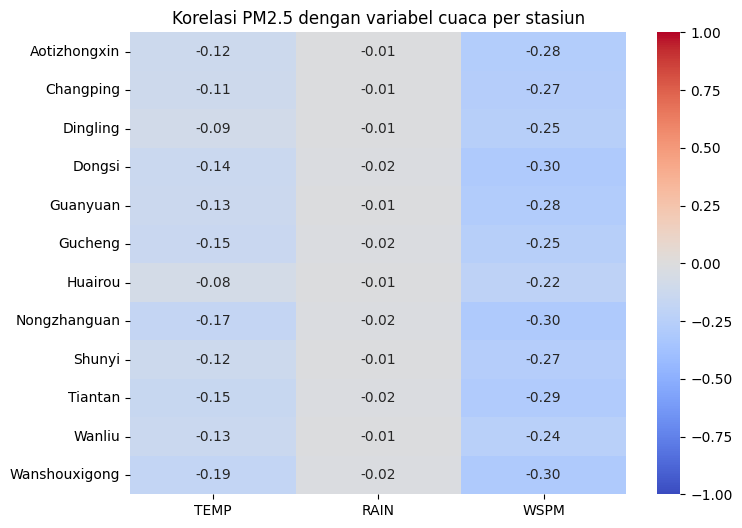

In [31]:
plt.figure(figsize=(8, 6))
sns.heatmap(korelasi_pm25, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Korelasi PM2.5 dengan variabel cuaca per stasiun')
plt.show()

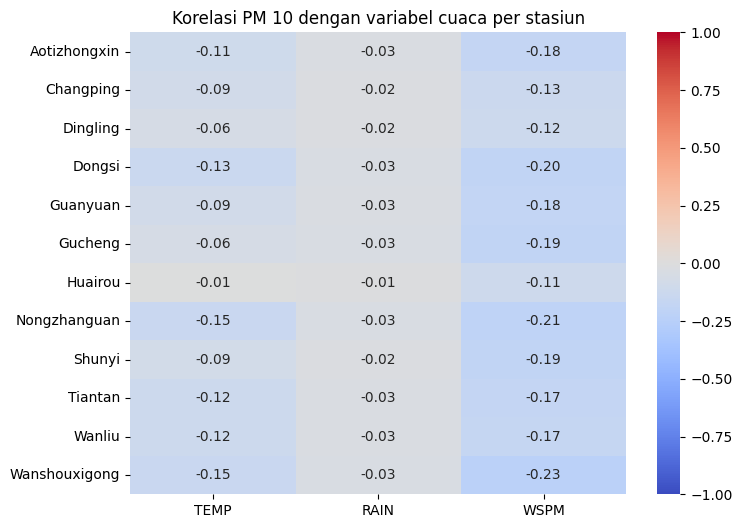

In [32]:
plt.figure(figsize=(8, 6))
sns.heatmap(korelasi_pm10, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Korelasi PM 10 dengan variabel cuaca per stasiun')
plt.show()

Dari hasil korelasi heatmap, ditunjukkan hasil korelasi yang cenderung lemah untuk temperatur, hujan, dan kecepatan angin. Hal ini berlaku baik untuk korelasi dengan polutan PM 10 maupun PM 2.5.

Pada hasil ini juga dapat dikatakan bahwa hubungan antara variabel cuaca dan polutan berkorelasi lemah dengan hubungan yang berkebalikan, menandakan adanya inversi antara polutan dan variabel cuaca.

In [33]:
def plot_klim(polutan, cuaca=['TEMP', 'WSPM', 'RAIN']):
    bulan_label = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun',
                   'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
    satuan = {'TEMP': '°C', 'WSPM': 'm/s', 'RAIN': 'mm/bulan'}
    warna_cuaca = {'TEMP': 'tab:red', 'DEWP': 'tab:green', 'PRES': 'tab:purple',
                   'WSPM': 'tab:orange', 'RAIN': 'tab:blue'}

    # polutan: per stasiun
    klim = gabung.groupby(['month', 'station'])[polutan].mean().unstack('station')

    # cuaca: total bulanan untuk RAIN, rata-rata untuk lainnya,
    # lalu dirata-rata antar tahun dan antar stasiun
    agg = {v: ('sum' if v == 'RAIN' else 'mean') for v in cuaca}
    cb = gabung.groupby(['station', 'year', 'month'])[cuaca].agg(agg)
    klim_cuaca = cb.groupby('month').mean()

    cmap = plt.get_cmap('tab20')
    n = 1 + len(cuaca)
    fig, axes = plt.subplots(n, 1, figsize=(13, 3 + 2.2 * n), sharex=True,
                             gridspec_kw={'height_ratios': [2.5] + [1] * len(cuaca)})

    # panel polutan
    ax = axes[0]
    for i, nama in enumerate(header_loaksi):
        ax.plot(klim.index, klim[nama], color=cmap(i), linewidth=1.2, alpha=0.8, label=nama)
    ax.plot(klim.index, klim.mean(axis=1), color='black', linewidth=3, label='Rata-rata stasiun')
    ax.set_ylabel(f'{polutan}\n(µg/m³)')
    ax.set_title(f'Klimatologi bulanan {polutan} dan variabel cuaca')
    ax.grid(alpha=0.3)
    ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False)

    # panel cuaca
    for ax, v in zip(axes[1:], cuaca):
        if v == 'RAIN':
            ax.bar(klim_cuaca.index, klim_cuaca[v], color=warna_cuaca[v], alpha=0.7)
        else:
            ax.plot(klim_cuaca.index, klim_cuaca[v], color=warna_cuaca[v], linewidth=2.5, marker='o')
        ax.set_ylabel(f'{v}\n({satuan.get(v, "")})')
        ax.grid(alpha=0.3)

    axes[-1].set_xticks(range(1, 13))
    axes[-1].set_xticklabels(bulan_label)
    plt.tight_layout()
    plt.show()

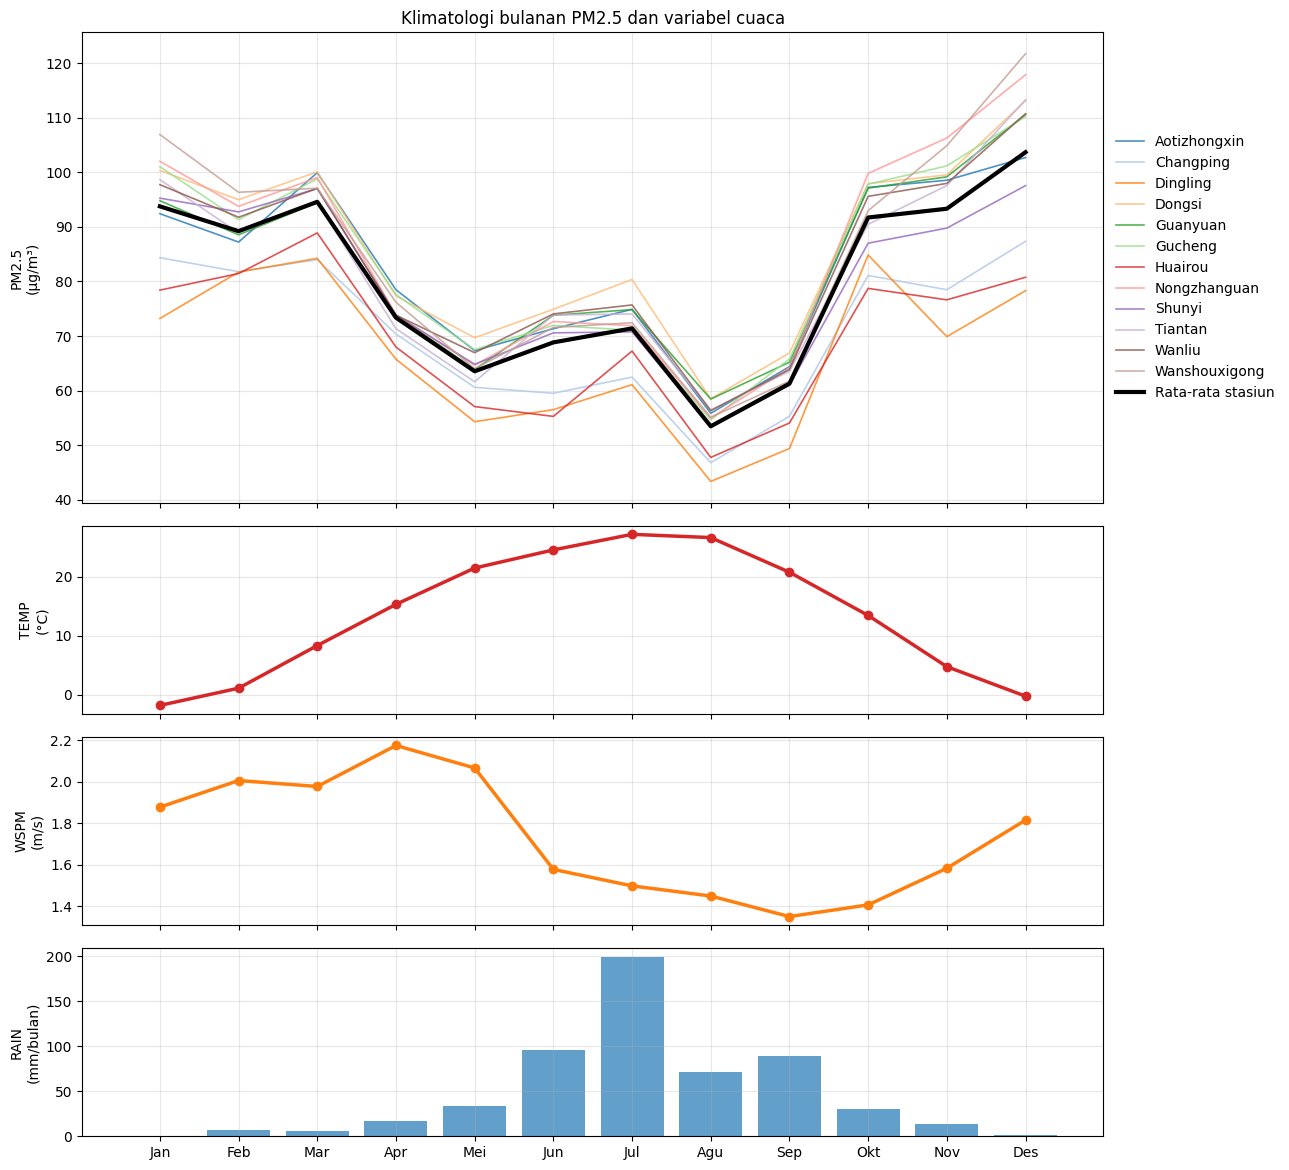

In [34]:
plot_klim('PM2.5', cuaca=['TEMP', 'WSPM', 'RAIN'])

Pada pola polutan PM2.5 terlihat adanya kenaikan dimulai dari bulan September dan mencapai puncak di bulan Desember atau Januari, lalu mulai mengalami penurunan dari bulan Maret sampai titik terendah di bulan Agustus.

Jika dilihat dari pola temperatur, nilai polutan mencapai titik terendah saat temperatur tinggi dan mencapai puncak saat temperatur rendah. Hal ini sejalan dengan nilai korelasi yang berkebalikan.

Sedangkan untuk pola angin, nilainya tidak terlalu mengikuti polutan dan terdapat lag, atau tidak serupa pada puncak dan titik terendah polutan.

Pada hujan, tidak ada kesesuaian antara pola polutan dengan hujan. Hal ini sesuai dengan korelasi hujan dan polutan.

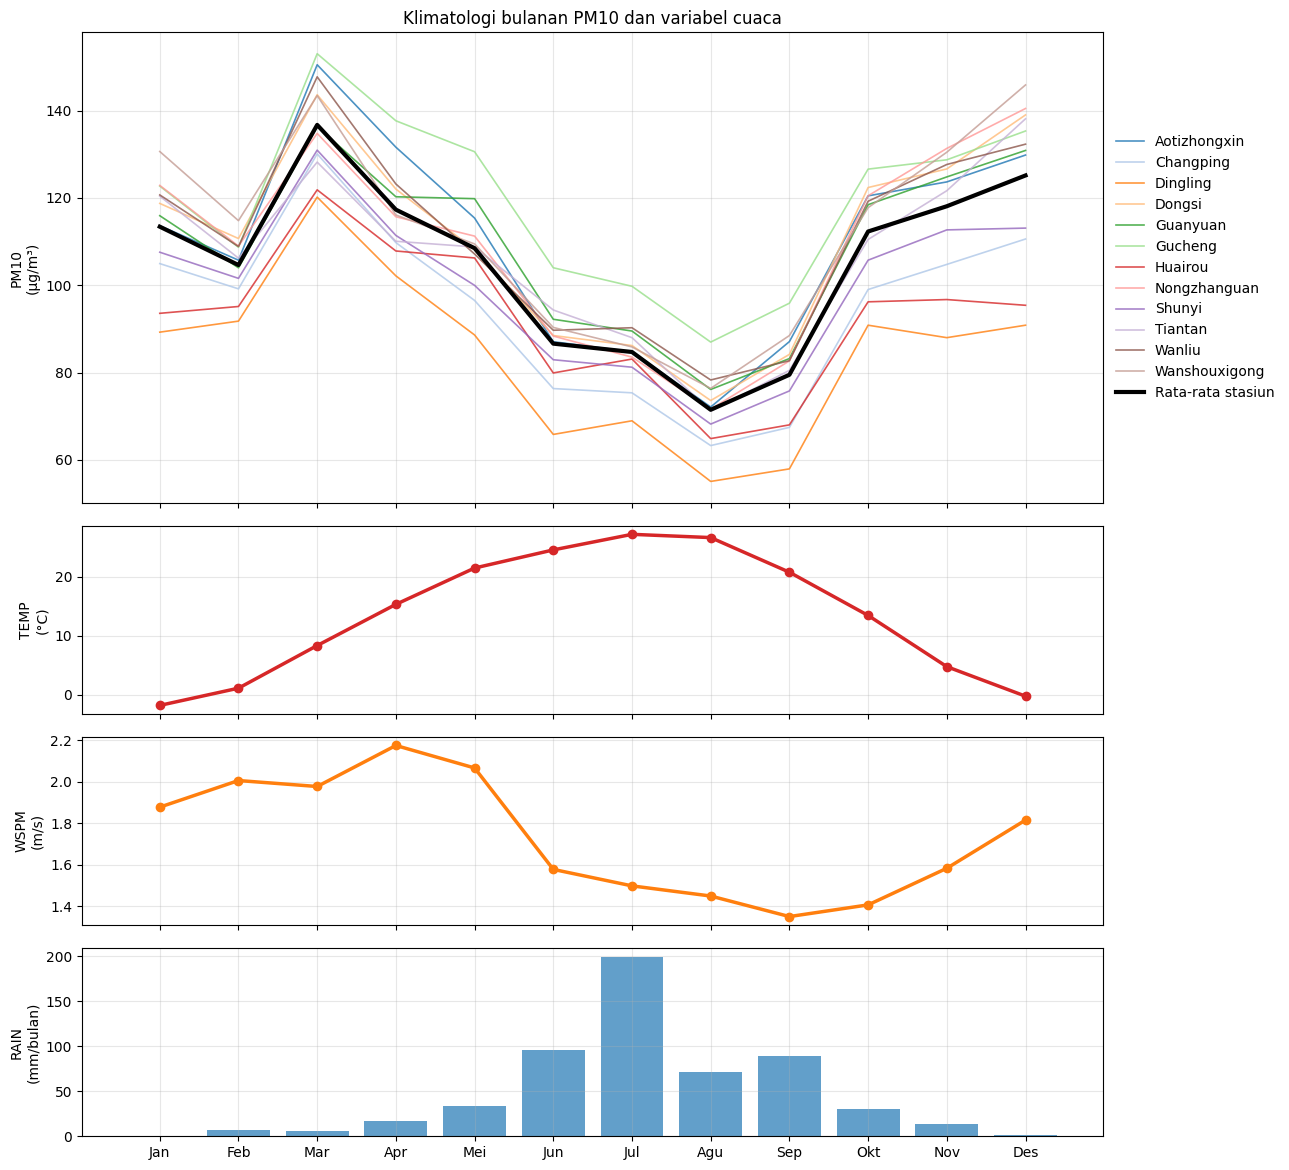

In [35]:
plot_klim('PM10', cuaca=['TEMP', 'WSPM', 'RAIN'])

Dari hasil plot line polutan PM10, temperatur, angin, dan plot bar hujan, dapat diketahui bahwa polutan memiliki pola yang serupa untuk semua wilayah, di mana terdapat pola kenaikan yang signifikan dari bulan September dan mencapai puncak di bulan Maret, lalu turun dan mencapai titik terendah di bulan Juli atau Agustus.

Pertanyaan 2: Berdasarkan arah angin dari seulurh wilayah bagaimana pergerakan dari dan ke particulate mater bergerak saat musim panas dan musim dingin

In [36]:
arah = ['N','NNE','NE','ENE','E','ESE','SE','SSE','S','SSW','SW','WSW','W','WNW','NW','NNW']
theta = np.deg2rad(np.arange(16) * 22.5)
musim = {'Musim dingin (Des–Feb)': [12, 1, 2],
         'Musim panas (Jun–Agu)':  [6, 7, 8]}

def plot_rose(polutan: str):
  data = {}
  for nama, bln in musim.items():
      d = gabung[gabung['month'].isin(bln)]
      frek = d['wd'].value_counts(normalize=True).reindex(arah).fillna(0) * 100
      pm = d.groupby('wd')[polutan].mean().reindex(arah)
      data[nama] = (frek, pm)

  # batas radial sama untuk kedua musim supaya bisa dibandingkan
  fmax = max(f.max() for f, _ in data.values()) * 1.1
  pmax = max(p.max() for _, p in data.values()) * 1.1

  baris = [('Frekuensi arah angin (%)', fmax, plt.cm.Blues, 0),
          (f'Rata-rata {polutan} (µg/m³)',  pmax, plt.cm.Reds,  1)]

  fig, axes = plt.subplots(2, 2, subplot_kw={'projection': 'polar'}, figsize=(12, 12))
  for j, (nama, nilai_musim) in enumerate(data.items()):
      for judul, rmax, cmap, i in baris:
          nilai = nilai_musim[i]
          ax = axes[i, j]
          ax.set_theta_zero_location('N')
          ax.set_theta_direction(-1)
          ax.bar(theta, nilai.values, width=np.deg2rad(22.5),
                color=cmap(nilai.values / rmax), edgecolor='white')
          ax.set_ylim(0, rmax)
          ax.set_xticks(theta)
          ax.set_xticklabels(arah)
          ax.set_title(f'{nama}\n{judul}', pad=20)

  plt.tight_layout()
  plt.show()

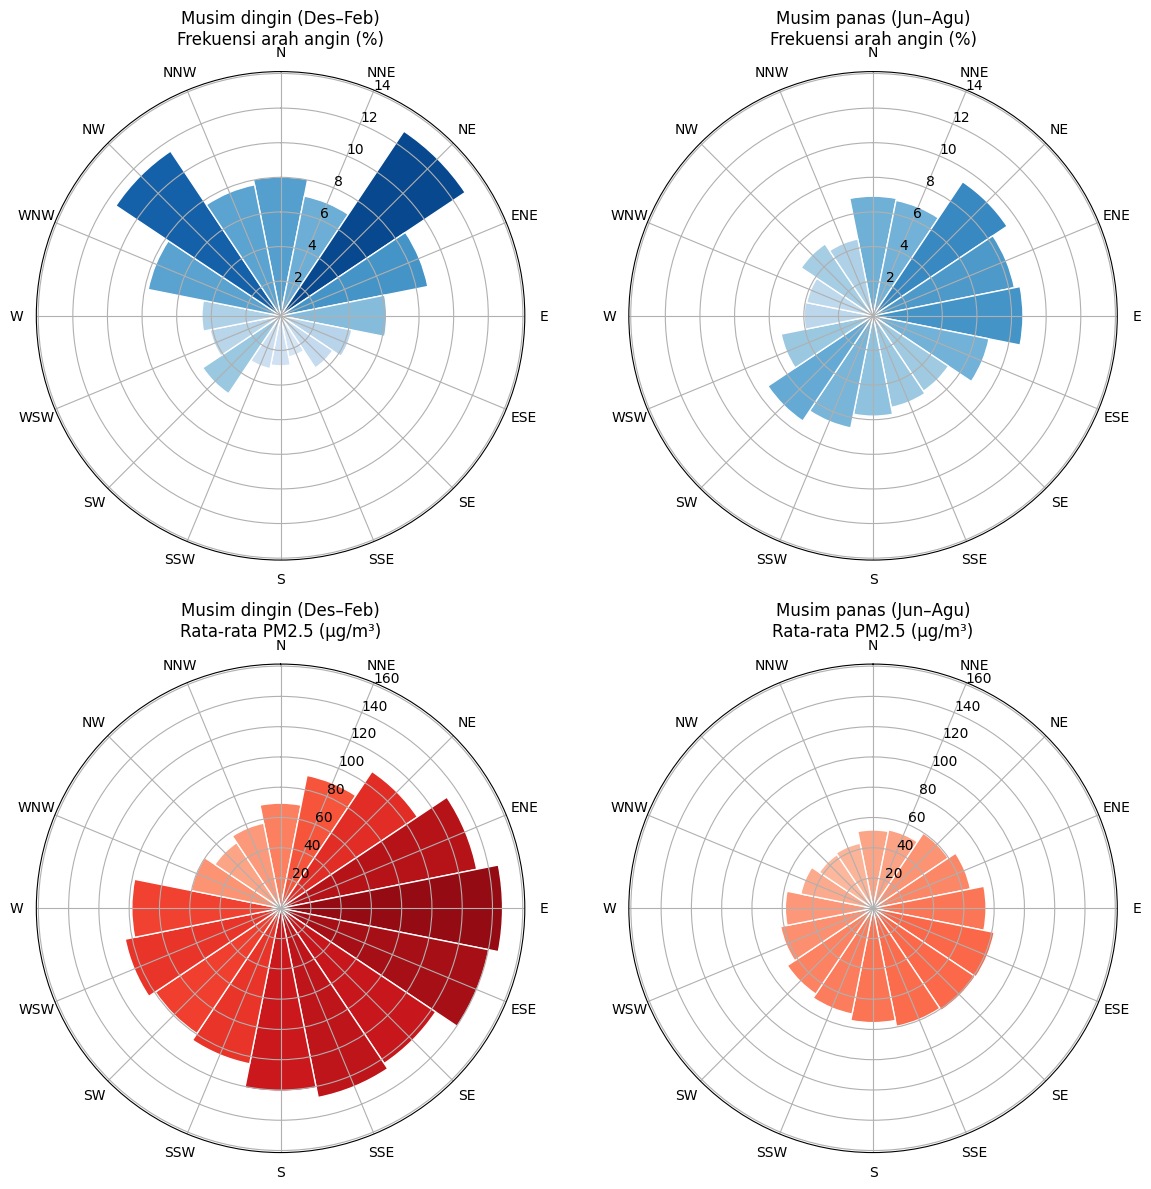

In [37]:
plot_rose("PM2.5")

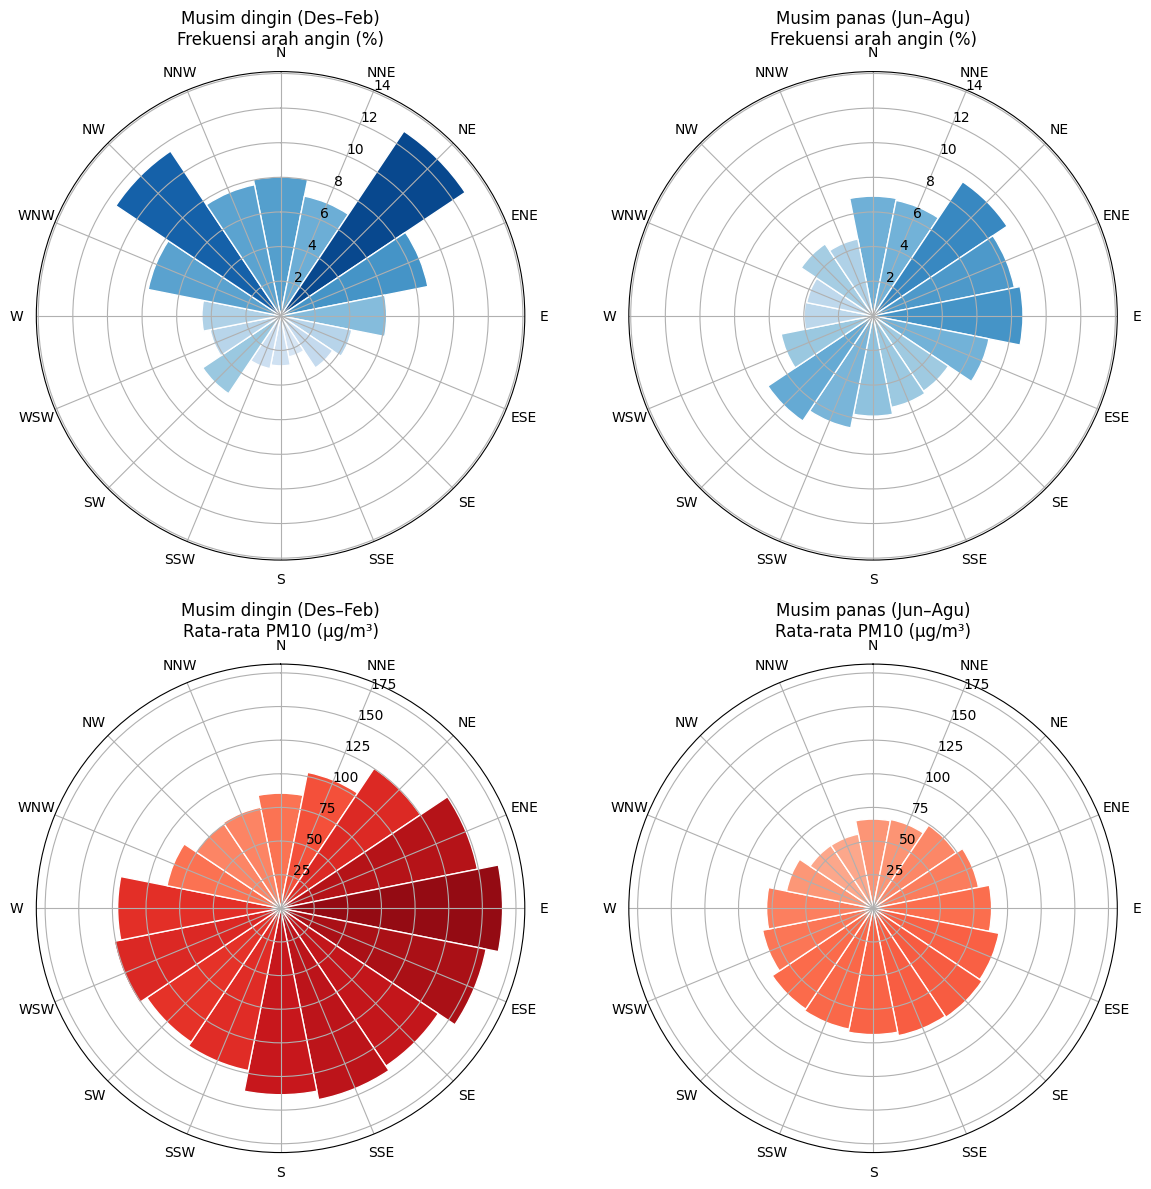

In [38]:
plot_rose("PM10")

Pada hasil peta windrose dan juga pollution rose, terlihat bahwa pergerakannya sama untuk PM 10 dan PM 2.5, di mana saat musim dingin kebanyakan angin bergerak dari barat laut ke utara dan timur laut, sedangkan pada musim panas dari utara ke timur laut.

Pada kedua musim itu juga polutan terlihat tinggi di musim dingin dengan hampir dominasi di seluruh arah angin, kecuali dari barat ke utara, sedangkan di musim panas pergerakan polutan cenderung lemah.

Hal ini sejalan dengan analisis bulanan, di mana polutan tinggi di akhir tahun sampai awal tahun, yaitu pada musim dingin, dan rendah pada musim panas di pertengahan tahun.

## Analisis Lanjutan (Opsional)

Pada analisis lanjutan di sini saya akan mencoba mengelompokan polutan berdasarkan kriteria dari US Air Quality Index, polutan akan dirata-rata dulu di setiap stasiun dan dilihat perbukan bagaiaman dan yang termasuk katrgori berbahaya yang mana

Berikut adalah index yang dipakai

| Nilai AQI | Kategori (Level of Concern) | Warna  | Keterangan |
|-----------|-----------------------------|--------|------------|
| 0 – 50    | Good                        | Hijau  | Kualitas udara memuaskan, polusi udara sedikit atau tidak berisiko. |
| 51 – 100  | Moderate                    | Kuning | Kualitas udara dapat diterima, tetapi bisa berisiko bagi sebagian kecil orang yang sangat sensitif terhadap polusi. |
| 101 – 150 | Unhealthy for Sensitive Groups | Oranye | Kelompok sensitif (anak-anak, lansia, penderita penyakit jantung/paru) dapat mengalami gangguan kesehatan. Masyarakat umum kemungkinan kecil terdampak. |
| 151 – 200 | Unhealthy                   | Merah  | Sebagian masyarakat umum dapat mengalami gangguan kesehatan; kelompok sensitif dapat mengalami dampak yang lebih serius. |
| 201 – 300 | Very Unhealthy              | Ungu   | Peringatan kesehatan: risiko dampak kesehatan meningkat bagi semua orang. |
| 301+      | Hazardous                   | Merah marun | Peringatan darurat kesehatan: semua orang lebih mungkin terdampak. |

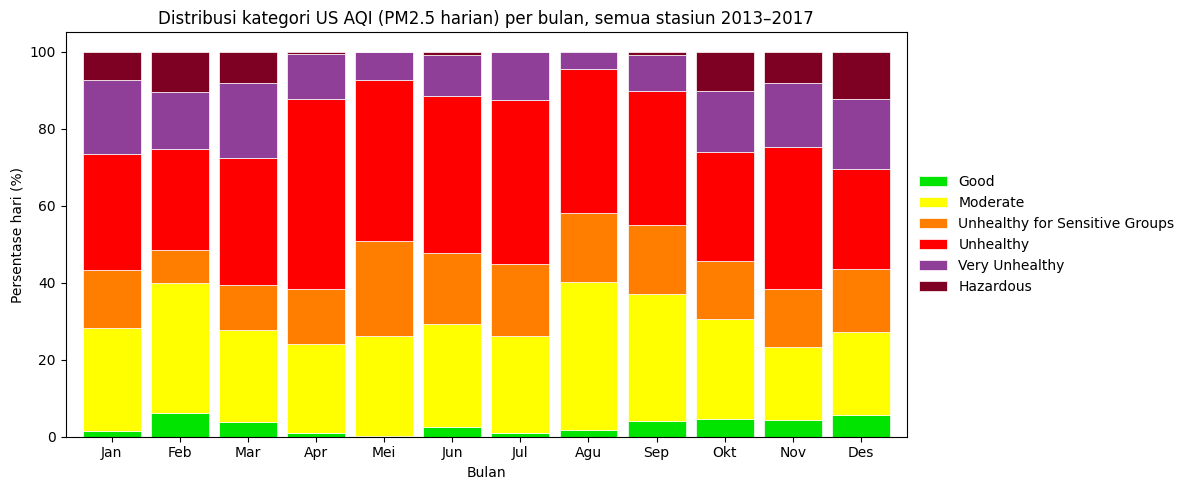

AQI,Good,Moderate,Unhealthy for Sensitive Groups,Unhealthy,Very Unhealthy,Hazardous
month,,,,,,
1,1.4,26.8,15.1,30.0,19.4,7.3
2,6.0,33.9,8.4,26.3,14.7,10.6
3,3.8,23.9,11.7,32.9,19.4,8.3
4,1.0,23.1,14.2,49.4,11.6,0.7
5,0.1,26.1,24.7,41.8,7.1,0.2
6,2.5,26.9,18.3,40.8,10.7,0.8
7,1.1,25.2,18.7,42.5,12.3,0.2
8,1.7,38.4,17.9,37.4,4.5,0.0
9,4.0,33.1,17.8,34.9,9.2,0.9


In [41]:
harian = (gabung.set_index('datetime')
                .groupby('station')['PM2.5']
                .resample('D').mean()
                .reset_index())
harian['month'] = harian['datetime'].dt.month

# 2. kategori US EPA AQI untuk PM2.5 (revisi 2024)
batas = [0, 9.0, 35.4, 55.4, 125.4, 225.4, np.inf]
label = ['Good', 'Moderate', 'Unhealthy for Sensitive Groups',
         'Unhealthy', 'Very Unhealthy', 'Hazardous']
harian['AQI'] = pd.cut(harian['PM2.5'], bins=batas, labels=label, include_lowest=True)

# 3. % hari per kategori per bulan (semua stasiun & tahun)
pct = pd.crosstab(harian['month'], harian['AQI'], normalize='index') * 100

# 4. plot dengan warna resmi EPA
warna_epa = ['#00e400', '#ffff00', '#ff7e00', '#ff0000', '#8f3f97', '#7e0023']
ax = pct.plot(kind='bar', stacked=True, color=warna_epa, width=0.85,
              figsize=(12, 5), edgecolor='white', linewidth=0.5)
ax.set_xticklabels(['Jan','Feb','Mar','Apr','Mei','Jun','Jul','Agu','Sep','Okt','Nov','Des'],
                   rotation=0)
ax.set_ylabel('Persentase hari (%)')
ax.set_xlabel('Bulan')
ax.set_title('Distribusi kategori US AQI (PM2.5 harian) per bulan, semua stasiun 2013–2017')
buruk = pct[['Unhealthy', 'Very Unhealthy', 'Hazardous']].sum(axis=1)
ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.tight_layout()
plt.show()

pct.round(1)

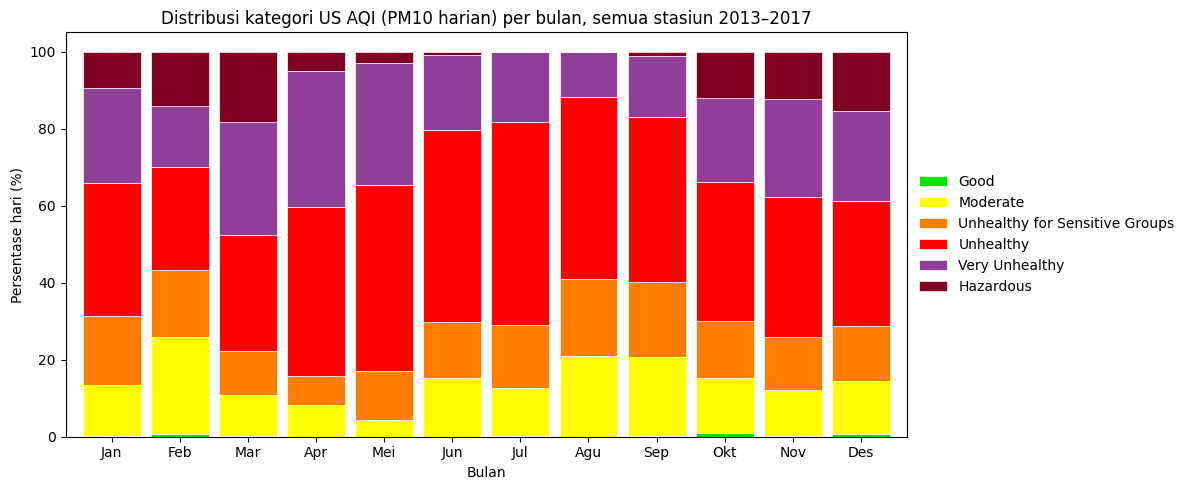

AQI,Good,Moderate,Unhealthy for Sensitive Groups,Unhealthy,Very Unhealthy,Hazardous
month,,,,,,
1,0.1,13.2,18.0,34.7,24.5,9.5
2,0.6,25.2,17.5,26.7,15.9,14.1
3,0.1,10.8,11.3,30.0,29.5,18.2
4,0.0,8.3,7.4,44.0,35.4,4.9
5,0.0,4.4,12.6,48.4,31.6,3.0
6,0.0,15.1,14.6,50.0,19.4,0.9
7,0.1,12.6,16.4,52.6,18.2,0.1
8,0.0,21.0,20.0,47.1,11.7,0.2
9,0.2,20.5,19.4,42.8,15.9,1.2


In [42]:
harian = (gabung.set_index('datetime')
                .groupby('station')['PM10']
                .resample('D').mean()
                .reset_index())
harian['month'] = harian['datetime'].dt.month

# 2. kategori US EPA AQI untuk PM2.5 (revisi 2024)
batas = [0, 9.0, 35.4, 55.4, 125.4, 225.4, np.inf]
label = ['Good', 'Moderate', 'Unhealthy for Sensitive Groups',
         'Unhealthy', 'Very Unhealthy', 'Hazardous']
harian['AQI'] = pd.cut(harian['PM10'], bins=batas, labels=label, include_lowest=True)

# 3. % hari per kategori per bulan (semua stasiun & tahun)
pct = pd.crosstab(harian['month'], harian['AQI'], normalize='index') * 100

# 4. plot dengan warna resmi EPA
warna_epa = ['#00e400', '#ffff00', '#ff7e00', '#ff0000', '#8f3f97', '#7e0023']
ax = pct.plot(kind='bar', stacked=True, color=warna_epa, width=0.85,
              figsize=(12, 5), edgecolor='white', linewidth=0.5)
ax.set_xticklabels(['Jan','Feb','Mar','Apr','Mei','Jun','Jul','Agu','Sep','Okt','Nov','Des'],
                   rotation=0)
ax.set_ylabel('Persentase hari (%)')
ax.set_xlabel('Bulan')
ax.set_title('Distribusi kategori US AQI (PM10 harian) per bulan, semua stasiun 2013–2017')
buruk = pct[['Unhealthy', 'Very Unhealthy', 'Hazardous']].sum(axis=1)
ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.tight_layout()
plt.show()

pct.round(1)

Berdasarkan hasil pengelompokan polutan dari Air Quality Index, terlihat bahwa pada bulan Oktober sampai Maret terdapat persentase yang tinggi untuk kategori hazardous yang mana ini amat sangat melebihi batas atas.

Dari hasil ini, maka dapat dikatakan bahwa pada bulan-bulan dengan kategori tinggi dapat menjadi peluang potensi pada edukasi masyarakat tentang bahaya pencemaran polutan PM 10 dan PM 2.5, serta untuk pemasaran penjualan masker dari perusahaan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Kesimpulan yang didapatkan dari pertanyaan 1 adalah, polutan PM 2.5 dan PM 10 tidak memiliki korelasi atau hubungan yang kuat dengan temperatur, hujan, dan angin, akan tetapi pola pergerakan variabel cuaca menunjukkan adanya keterkaitan dengan sistem yang lebih luas, di mana pada musim gugur dan dingin nilai polutan naik dan mencapai titik tertinggi, lalu turun kembali dan mencapai titik terendah di musim panas.



- **Conclusion pertanyaan 2:** Pada pertanyaan kedua, pergerakan polutan di musim dingin cenderung tersebar dari semua wilayah, sedangkan pada musim panas lemah di semua arah angin.

Dari hasil kedua ini juga dapat disimpulkan untuk bisnis masker yang menjadi dasar analisis adalah penjualan dapat diboost di waktu polutan tinggi, yaitu saat musim gugur dan musim dingin. Hal ini dapat dilakukan dengan mengedukasi masyarakat di saat polutan rendah di musim panas sehingga saat musim dingin masyarakat aware dan mulai adanya peningkatan pembelian.

**Rekomendasi Action Item:**
- Perlunya dilakukan penelitian lebih lanjut dengan acuan yang lebih detail dan data yang lebih panjang.
- Pada edukasi ke masyarakat, perlu ditekankan bahwa polutan PM 10 dan PM 2.5 berbahaya, lalu perlu ditekankan pada bulan-bulan yang benar-benar terlihat berbahaya.
- Perlunya memakai data cuaca lain agar lebih terlihat faktor cuaca apa yang benar-benar memengaruhi polutan.
- Jika memungkinkan, perlunya penggunaan machine learning, terutama untuk mengisi data kosong, karena dengan metode sekarang terlalu robust.

In [43]:
with pd.ExcelWriter('data_kualitas_udara_beijing.xlsx', engine='openpyxl') as writer:
    for nama, d in zip(header_loaksi, df):
        d.to_excel(writer, sheet_name=nama)